# Import packages

In [1]:
import numpy as np
import time
import traceback
import scipy.linalg

# Parameters

In [2]:
total_steps=1000
save_steps=100
epsilon=0.1
relaxation_steps=10
density_threshold=1e30
total_time=0.0
a=2.257
b=1.385
c=0.753
sigma=0.5
mass_norm=0.1
scale_norm=0.1
tag='2026xxxx'
input_dir='C:/Users/user/Desktop/.venv/gravothermal-main/result/initial/' + tag + '/'
output_file='C:/Users/user/Desktop/.venv/gravothermal-main/result/'+tag+'.txt'

# Programs

In [3]:
def display():
  print('Initial profile:',tag)
  print('Initial time:',total_time)
  print('Total step:',total_steps)
  print('Save step:',save_steps)
  print('Abs(delta u/u):',epsilon)
  print('Cross section (sigma):',sigma)
  print('Conduction parameter (a,b,c):',a,',',b,',',c)
  print('Baryon parameter (mass_norm,scale):',mass_norm,',',scale_norm)


In [4]:
def MbaryonP(myr,mymass,myscale):
  return mymass*(1.+myscale**2/myr**2)**-1.5
def MbaryonH(myr,mymass,myscale):
  return mymass*(1.+myscale/myr)**-2.
def MbaryonSPL(myr,mymass):
  return mymass*myr**.6


In [5]:
class SimulationState:
  def initialize(self):
    try:
      self.nameR=input_dir+'RList-'+str(tag)+'.txt'
      self.nameRho=input_dir+'RhoList-'+str(tag)+'.txt'
      self.nameM=input_dir+'MList-'+str(tag)+'.txt'
      self.nameu=input_dir+'uList-'+str(tag)+'.txt'
      self.nameL=input_dir+'LList-'+str(tag)+'.txt'

      self.RList = np.loadtxt(self.nameR, dtype=np.longdouble)
      self.RhoList = np.loadtxt(self.nameRho, dtype=np.longdouble)
      self.MList = np.loadtxt(self.nameM, dtype=np.longdouble)
      self.uList = np.loadtxt(self.nameu, dtype=np.longdouble)
      self.LList = np.loadtxt(self.nameL, dtype=np.longdouble)
      
      self.NoLayers=len(self.RList)

      self.MhyList = np.zeros(self.NoLayers, dtype=np.longdouble)
      self.vList = np.zeros(self.NoLayers, dtype=np.longdouble)
      self.pList = np.zeros(self.NoLayers, dtype=np.longdouble)
      self.aList = np.zeros(self.NoLayers, dtype=np.longdouble)
      self.vList=np.sqrt(2./3.)*np.sqrt(self.uList)

      self.MhyList[:-1] = self.MList[:-1] + MbaryonP(self.RList[:-1], mass_norm, scale_norm)

      print('Number of layers:',self.NoLayers)
      print('Initial r inner most:',self.RList[0])
      print('Initial r next to outer most:',self.RList[-2])
      print('Initial rho inner most:',self.RhoList[0])
      print('Initial rho next to outer most:',self.RhoList[-2])

    except Exception as e:
      print('Failed to initialize simulation state:',e)

  def checkForAbnormalState(self):
    if self.RhoList[0]>density_threshold:
      print('Rho reaches threshold!')
      return True

    if self.RList[0]<0:
      print('R[0] is negative!')
      return True

    if np.isnan(self.RList[0]):
      print('R is nan!')
      return True

    return False

In [6]:
class Simulator:
  def __init__(self,state):
    self.state=state

  def initialize(self,state):
    state.initialize()
    NoLayers=self.state.NoLayers

    self.deltaUcoeff=np.zeros(NoLayers, dtype=np.longdouble)
    self.deltaU=np.zeros(NoLayers, dtype=np.longdouble)
    self.hydrostaticI=np.zeros(NoLayers, dtype=np.longdouble)
    self.hydrostaticM=np.zeros(NoLayers, dtype=np.longdouble)
    self.hydrostaticF=np.zeros(NoLayers, dtype=np.longdouble)

    self.Hydromat=np.zeros((NoLayers,NoLayers), dtype=np.longdouble)
    self.Hydrob=np.zeros(NoLayers, dtype=np.longdouble)
    self.deltaR=np.zeros(NoLayers, dtype=np.longdouble)
    self.deltap=np.zeros(NoLayers, dtype=np.longdouble)
    self.deltaRho=np.zeros(NoLayers, dtype=np.longdouble)

    self.total_time = total_time

    self.file=open(output_file, "w")
    self.file.write('Input profile name:'+str(tag)+'\n'+
    'Initial time:'+str(self.total_time)+'\n'+
    'Number of layers:'+str(state.NoLayers)+'\n'+
    'Initial r inner most:'+str(state.RList[0])+'\n'+
    'Initial r outer most:'+str(state.RList[NoLayers-1])+'\n'+
    'Initial rho inner most:'+str(state.RhoList[0])+'\n'+
    'Initial rho outer most:'+str(state.RhoList[NoLayers-1])+'\n'+
    'Total step:'+str(total_steps)+'\n'+
    'Save step:'+str(save_steps)+'\n'+
    'Abs(delta u/u):'+str(epsilon)+'\n'+
    'Cross section (sigma):'+str(sigma)+'\n'+
    'Conduction parameter (a,b,c):'+str(a)+','+str(b)+','+str(c)+'\n'+
    'Baryon parameter (mass_norm,scale_norm):'+str(mass_norm)+','+str(scale_norm)+'\n'+
    'time, step, SIDM radius, SIDM density, SIDM enclosed mass, SIDM internal energy, SIDM luminosity'+'\n'+
    str(self.total_time)+' '+str(0)+'\n'+
    str(state.RList.T)+'\n'+str(state.RhoList.T)+'\n'+str(state.MList)+'\n'+str(state.uList)+'\n'+str(state.LList)+'\n')

    print('Evolution with baryon starts!')

  def runSimulation(self,state):
    currentSaveStep=save_steps

    for tstep in range(1,total_steps+1):
      try:
        deltat=self.performConductionStep(state)
        self.total_time=self.total_time+deltat

        self.performRelaxationStep(state)

        self.updateProfiles(state)

        if state.RhoList[0]>=1e6 and currentSaveStep!=1:
          currentSaveStep=1
          print('Density threshold 1e6 reached! Save frequency increased to every step.')

        if state.checkForAbnormalState():
          break

        if (tstep%currentSaveStep)==0:
          self.saveResults(state,tstep)
          print('Saved at time=',self.total_time,',','step=',tstep)

      except Exception as e:
        print('Error during simulation step:',tstep,':',e)
        import traceback
        traceback.print_exc()
        break

    self.file.close()
    print('Evolution ends')

  def performConductionStep(self, state):
    NoLayers = state.NoLayers

    self.deltaUcoeff[0] = -(state.LList[1]) / state.MList[1] / state.uList[0]

    j = np.arange(1, NoLayers - 1)
    self.deltaUcoeff[j] = -(state.LList[j+1] - state.LList[j-1]) / (state.MList[j+1] - state.MList[j-1]) / state.uList[j]

    # Lock the delta U coefficient at the outer boundary to 0
    self.deltaUcoeff[-1] = 0.0

    deltat = epsilon / (np.max(np.abs(self.deltaUcoeff)) + 1e-30)

    self.solve_u_implicit(state, deltat)

    state.pList = (2./3.) * (state.RhoList * state.uList)
    state.aList = (2./3.) * (state.RhoList)**(-2./3.) * state.uList
    return deltat

  def solve_u_implicit(self, state, deltat):
   
    NoLayers = state.NoLayers
    dt = deltat

    vi = np.sqrt(2./3.) * np.sqrt(state.uList)
    kappa = a * b * c * sigma * (state.RhoList * vi**3 / (a * c * sigma**2 * state.RhoList * vi**2 + b))

    u = state.uList
    M = state.MList
    r = state.RList

    C = np.zeros(NoLayers)
    ab = np.zeros((3, NoLayers))

    r_plus_0 = 0.5 * (r[0] + r[1])
    kappa_plus_0 = 0.5 * (kappa[0] + kappa[1])
    dr_plus_0 = r[1] - r[0]
    dM_0 = M[1]

    alpha_plus_0 = dt * kappa_plus_0 * (r_plus_0**2) / (dM_0 * dr_plus_0)
    ab[1, 0] = 1.0 + alpha_plus_0
    ab[0, 1] = -alpha_plus_0
    C[0] = u[0]

    j = np.arange(1, NoLayers - 1)

    r_minus = 0.5 * (r[j] + r[j-1])
    r_plus  = 0.5 * (r[j] + r[j+1])
    kappa_minus = 0.5 * (kappa[j] + kappa[j-1])
    kappa_plus  = 0.5 * (kappa[j] + kappa[j+1])

    dr_minus = r[j] - r[j-1]
    dr_plus  = r[j+1] - r[j]
    dM       = M[j+1] - M[j-1]

    alpha_minus = dt * kappa_minus * (r_minus**2) / (dM * dr_minus)
    alpha_plus  = dt * kappa_plus  * (r_plus**2)  / (dM * dr_plus)

    ab[0, j+1] = -alpha_plus
    ab[1, j]   = 1.0 + alpha_minus + alpha_plus
    ab[2, j-1] = -alpha_minus
    C[j] = u[j]

    # STRICT OUTER BOUNDARY CONDITION: Fix internal energy so it cannot fluctuate
    ab[2, -2] = 0.0
    ab[1, -1] = 1.0
    C[-1] = u[-1]

    state.uList = scipy.linalg.solve_banded((1, 1), ab, C)

  def performRelaxationStep(self,state):
    NoLayers=state.NoLayers

    for hstep in range(0,relaxation_steps):
      try:
        self.setupHydrostaticMatrix(state)

        # Robust SVD-based solver to handle matrix ill-conditioning
        self.deltaR, residuals, rank, s = np.linalg.lstsq(self.Hydromat, self.Hydrob, rcond=None)

        self.calculateDeltaRhoAndP(state)

        with np.errstate(divide='ignore', invalid='ignore'):
            rel_dr = np.nan_to_num(np.abs(self.deltaR / state.RList), nan=0.0, posinf=0.0, neginf=0.0)
            rel_drho = np.nan_to_num(np.abs(self.deltaRho / state.RhoList), nan=0.0, posinf=0.0, neginf=0.0)
            rel_dp = np.nan_to_num(np.abs(self.deltap / state.pList), nan=0.0, posinf=0.0, neginf=0.0)

        # Apply maximum relative change exclusively to the interior nodes
        max_rel_change = max(np.max(rel_dr[:-1]), np.max(rel_drho[:-1]), np.max(rel_dp[:-1]))

        limit = 0.01
        if max_rel_change > limit:
            scale = limit / max_rel_change
            self.deltaRho *= scale
            self.deltap *= scale
            self.deltaR *= scale

        state.RhoList[:] += self.deltaRho[:]
        state.pList[:] += self.deltap[:]
        state.RList[:] += self.deltaR[:]

      except Exception as e:
        print('Error during relaxation step:',hstep,':',e)
        import traceback
        traceback.print_exc()
        break

  def setupHydrostaticMatrix(self,state):
    NoLayers=state.NoLayers
    p=state.pList
    r=state.RList
    M=state.MhyList
    rho=state.RhoList

    self.Hydromat.fill(0.0)

    self.Hydromat[0,0]= (
        (p[1]-p[0])*2*r[0]
        + 5*r[0]**2*p[1]/3/(r[2]-r[0])
        - 5*r[0]**2*p[0]/3/r[1]
        + 10*r[0]*p[0]/3
        - M[0]*rho[0]*r[0]/r[1]
        - 2*M[0]*rho[0]*(r[1]-r[0])/r[0]
    )
    self.Hydromat[0,1] = -10*r[0]**2*p[1]/3/r[1] + 5*r[0]**2*p[0]/3/r[1] + M[0]*rho[0]*r[0]/r[1]
    self.Hydromat[0,2] = -5*r[0]**2*p[1]/3/(r[2]-r[0])

    self.Hydromat[1,0] = -5*r[1]*p[0]/3 + 10*r[1]**2*p[0]/3/r[0]
    self.Hydromat[1,1] = (
        (p[2]-p[0])*2*r[1]
        + 5*r[1]**2*p[2]/3/(r[3]-r[1])
        + 5*r[1]*p[0]/3
        - 2*M[1]*rho[1]*(r[2]-r[0])/r[1]
    )
    self.Hydromat[1,2] = -10*r[1]**2*p[2]/3/r[2]
    self.Hydromat[1,3] = -5*r[1]**2*p[2]/3/(r[3]-r[1])

    j=np.arange(2,NoLayers-2)
    self.Hydromat[j,j-2] = -5*r[j]**2*p[j-1]/3/(r[j]-r[j-2])
    self.Hydromat[j,j-1] = 10*r[j]**2*p[j-1]/3/r[j-1]
    self.Hydromat[j,j] = (
        (p[j+1]-p[j-1])*2*r[j]
        + 5*r[j]**2*p[j+1]/3/(r[j+2]-r[j])
        + 5*r[j]**2*p[j-1]/3/(r[j]-r[j-2])
        - 2*M[j]*rho[j]*(r[j+1]-r[j-1])/r[j]
    )
    self.Hydromat[j,j+1] = -10*r[j]**2*p[j+1]/3/r[j+1]
    self.Hydromat[j,j+2] = -5*r[j]**2*p[j+1]/3/(r[j+2]-r[j])

    self.Hydromat[-2,-4] = -5*r[-2]**2*p[-3]/3/(r[-2]-r[-4])
    self.Hydromat[-2,-3] = 10*r[-2]**2*p[-3]/3/r[-3]
    self.Hydromat[-2,-2] = (
        (p[-1]-p[-3])*2*r[-2]
        + 5*r[-2]**2*p[-1]/3/(r[-1]-r[-2])
        + 5*r[-2]**2*p[-3]/3/(r[-2]-r[-4])
        - 2*M[-2]*rho[-2]*(r[-1]-r[-3])/r[-2]
    )
    self.Hydromat[-2,-1] = -10*r[-2]**2*p[-1]/3/r[-1] - 5*r[-2]**2*p[-1]/3/(r[-1]-r[-2])

    self.Hydrob[0] = -(p[1]-p[0])*r[0]**2 - M[0]*rho[0]*r[1]
    j = np.arange(1,NoLayers-1)
    self.Hydrob[j] = -(p[j+1]-p[j-1])*r[j]**2 - M[j]*rho[j]*(r[j+1]-r[j-1])

    # STRICT OUTER BOUNDARY CONDITION: Pin radius precisely to delta R[N] = 0
    self.Hydromat[-1, :] = 0.0
    self.Hydromat[-1, -1] = 1.0
    self.Hydrob[-1] = 0.0

    row_maxs = np.max(np.abs(self.Hydromat), axis=1, keepdims=True) + 1e-50
    self.Hydromat /= row_maxs
    self.Hydrob /= row_maxs.flatten()

  def calculateDeltaRhoAndP(self,state):
    NoLayers=state.NoLayers
    rho=state.RhoList
    p=state.pList
    r=state.RList
    dr=self.deltaR

    self.deltaRho[0]=rho[0]*(dr[0]/r[1] - 2*dr[0]/r[0] - dr[1]/r[1])
    self.deltap[0]=5/3*p[0]*(dr[0]/r[1] - 2*dr[0]/r[0] - dr[1]/r[1])

    j=np.arange(1,NoLayers-1)
    self.deltaRho[j]=rho[j]*(dr[j-1]/(r[j+1]-r[j-1]) - 2*dr[j]/r[j] - dr[j+1]/(r[j+1]-r[j-1]))
    self.deltap[j]=5/3*p[j]*(dr[j-1]/(r[j+1]-r[j-1]) - 2*dr[j]/r[j] - dr[j+1]/(r[j+1]-r[j-1]))

    # STRICT OUTER BOUNDARY CONDITION: Clamp delta Rho[N] = 0, delta p[N] = 0
    self.deltaRho[-1] = 0.0
    self.deltap[-1] = 0.0

  def updateProfiles(self,state):
    NoLayers=state.NoLayers

    i=np.arange(0,NoLayers-1)
    state.MhyList[i]=state.MList[i]+MbaryonP(state.RList[i],mass_norm,scale_norm)

    safe_rho = np.maximum(state.RhoList, 1e-30)

    state.uList = 1.5 * state.aList * safe_rho**(2./3.)
    state.vList = np.sqrt(2./3.) * np.sqrt(state.uList)

    r=state.RList
    v=state.vList
    rho=state.RhoList
    u=state.uList

    kappa = (
        a * b * c * sigma *
        (rho * v**3 / (a * c * sigma**2 * rho * v**2 + b))
    )

    state.LList[0]=-(u[1]-u[0])/(r[1]-r[0])*r[0]**2*kappa[0]
    j=np.arange(1,NoLayers-1)
    state.LList[j]=-(u[j+1]-u[j-1])/(r[j+1]-r[j-1])*r[j]**2*kappa[j]

    # STRICT OUTER BOUNDARY CONDITION: Enforce reflecting boundary L[N] = 0
    state.LList[-1] = 0.0

  def saveResults(self,state,tstep):
    self.file.write(
    str(self.total_time)+' '+str(tstep)+'\n'
    +str(state.RList.T)+'\n'
    +str(state.RhoList.T)+'\n'
    +str(state.MList.T)+'\n'
    +str(state.uList.T)+'\n'
    +str(state.LList.T)+'\n'
    )

# Main

In [7]:
def main():
  start=time.time()
  try:
    display()
    state=SimulationState()
    simulator=Simulator(state)
    simulator.initialize(state)
    simulator.runSimulation(state)
    end=time.time()
    print('Computation time:'+str(end-start)+'s')
  except Exception as e:
    print('Error:',e)

In [8]:
main()

Initial profile: 2026xxxx
Initial time: 0.0
Total step: 1000
Save step: 100
Abs(delta u/u): 0.1
Cross section (sigma): 0.5
Conduction parameter (a,b,c): 2.257 , 1.385 , 0.753
Baryon parameter (mass_norm,scale): 0.1 , 0.1
Number of layers: 150
Initial r inner most: 0.005
Initial r next to outer most: 225.4540569
Initial rho inner most: 398.0074751
Initial rho next to outer most: 9.61964548e-08
Evolution with baryon starts!
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step

Traceback (most recent call last):
  File "C:\Users\user\AppData\Local\Temp\ipykernel_4004\905872487.py", line 153, in performRelaxationStep
    self.deltaR, residuals, rank, s = np.linalg.lstsq(self.Hydromat, self.Hydrob, rcond=None)
  File "c:\Users\user\Desktop\.venv\lib\site-packages\numpy\linalg\_linalg.py", line 2502, in lstsq
    t, result_t = _commonType(a, b)
  File "c:\Users\user\Desktop\.venv\lib\site-packages\numpy\linalg\_linalg.py", line 162, in _commonType
    raise TypeError("array type %s is unsupported in linalg" %
TypeError: array type float64 is unsupported in linalg
Traceback (most recent call last):
  File "C:\Users\user\AppData\Local\Temp\ipykernel_4004\905872487.py", line 153, in performRelaxationStep
    self.deltaR, residuals, rank, s = np.linalg.lstsq(self.Hydromat, self.Hydrob, rcond=None)
  File "c:\Users\user\Desktop\.venv\lib\site-packages\numpy\linalg\_linalg.py", line 2502, in lstsq
    t, result_t = _commonType(a, b)
  File "c:\Users\user\Desktop\.venv

Saved at time= 17388812.077197142 , step= 500
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relaxation step: 0 : array type float64 is unsupported in linalg
Error during relax

Traceback (most recent call last):
  File "C:\Users\user\AppData\Local\Temp\ipykernel_4004\905872487.py", line 153, in performRelaxationStep
    self.deltaR, residuals, rank, s = np.linalg.lstsq(self.Hydromat, self.Hydrob, rcond=None)
  File "c:\Users\user\Desktop\.venv\lib\site-packages\numpy\linalg\_linalg.py", line 2502, in lstsq
    t, result_t = _commonType(a, b)
  File "c:\Users\user\Desktop\.venv\lib\site-packages\numpy\linalg\_linalg.py", line 162, in _commonType
    raise TypeError("array type %s is unsupported in linalg" %
TypeError: array type float64 is unsupported in linalg
Traceback (most recent call last):
  File "C:\Users\user\AppData\Local\Temp\ipykernel_4004\905872487.py", line 153, in performRelaxationStep
    self.deltaR, residuals, rank, s = np.linalg.lstsq(self.Hydromat, self.Hydrob, rcond=None)
  File "c:\Users\user\Desktop\.venv\lib\site-packages\numpy\linalg\_linalg.py", line 2502, in lstsq
    t, result_t = _commonType(a, b)
  File "c:\Users\user\Desktop\.venv

# Read file and plot graph

Successfully loaded 11 time snapshots.


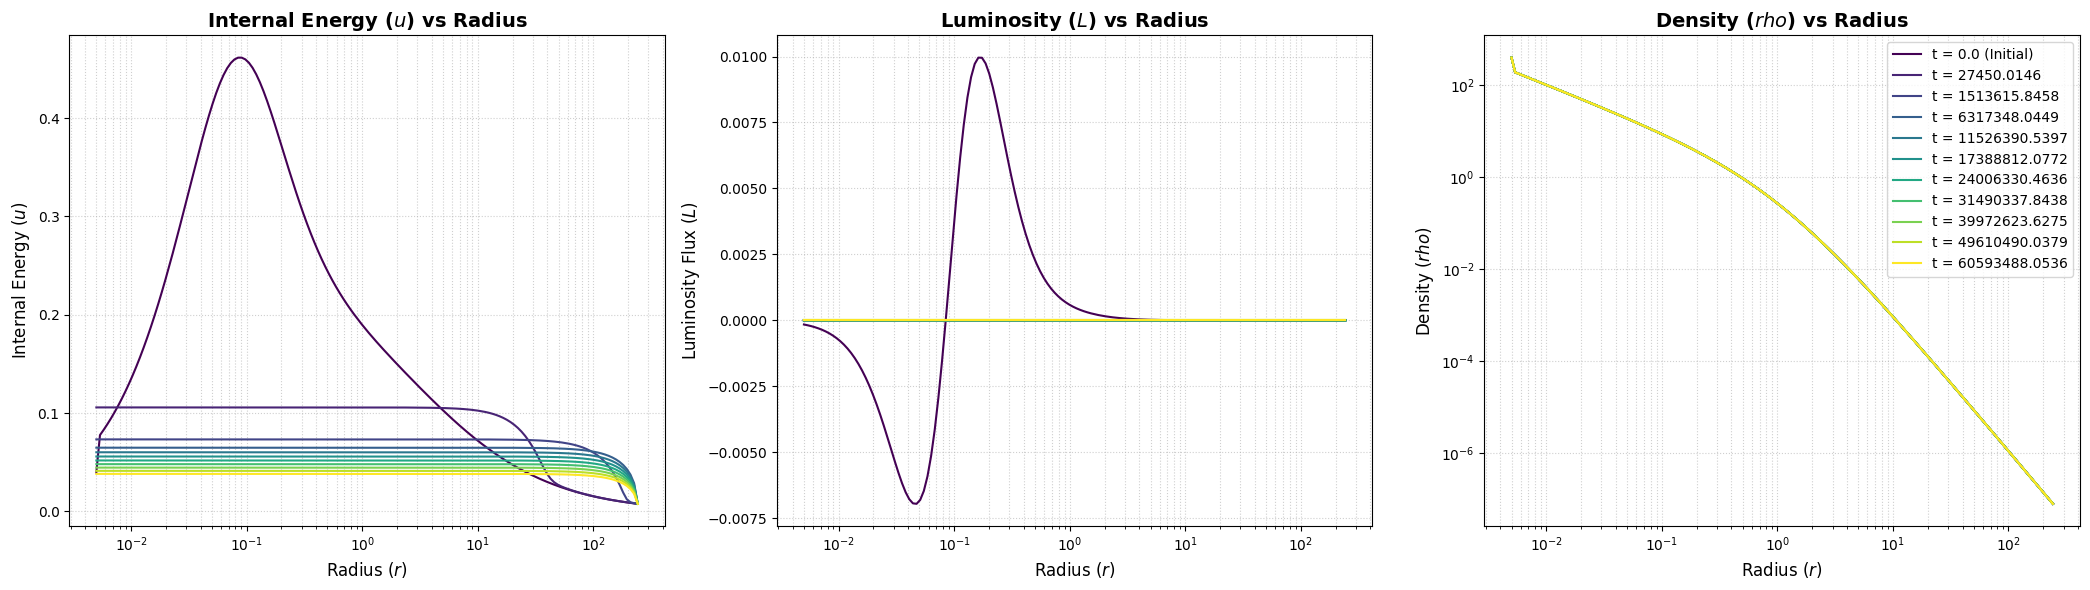

In [9]:
import matplotlib.pyplot as plt
import re

# 1. File Path - Update this to match your actual output file path

def read_gravothermal_output(filename):
    with open(output_file, 'r') as f:
        lines = f.readlines()

    # Skip the 14 header lines
    raw_data = "".join(lines[14:])

    # Extract all arrays enclosed in brackets [ ... ]
    # re.DOTALL ensures it captures arrays that span across multiple newlines
    array_strings = re.findall(r'\[(.*?)\]', raw_data, re.DOTALL)

    # Remove all the arrays from the text to leave behind only the time/step lines
    time_step_text = re.sub(r'\[.*?\]', '', raw_data, flags=re.DOTALL)

    # Clean up empty lines to get a list of "time step" strings
    time_lines = [line.strip() for line in time_step_text.split('\n') if line.strip()]

    snapshots = []

    # Each time snapshot consists of 1 time line and 5 arrays (R, Rho, M, u, L)
    for i, t_line in enumerate(time_lines):
        # Parse time and step
        t_val, step_val = map(float, t_line.split())

        # Get the corresponding 5 arrays using the index multiplier
        idx = i * 5
        r_arr = np.fromstring(array_strings[idx], sep=' ')
        rho_arr = np.fromstring(array_strings[idx+1], sep=' ')
        m_arr = np.fromstring(array_strings[idx+2], sep=' ')
        u_arr = np.fromstring(array_strings[idx+3], sep=' ')
        l_arr = np.fromstring(array_strings[idx+4], sep=' ')

        snapshots.append({
            'time': t_val,
            'step': int(step_val),
            'r': r_arr,
            'rho': rho_arr,
            'M': m_arr,
            'u': u_arr,
            'L': l_arr
        })

    return snapshots

# 2. Extract Data
snapshots = read_gravothermal_output(output_file)
print(f"Successfully loaded {len(snapshots)} time snapshots.")

# 3. Create Plots
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Generate a color map so early times are one color and late times are another
colors = plt.cm.viridis(np.linspace(0, 1, len(snapshots)))

for i, snap in enumerate(snapshots):
    t_label = f"t = {snap['time']:.4f}" if snap['time'] > 0 else "t = 0.0 (Initial)"

    # Panel 1: Internal Energy (u) vs Radius (r)
    axes[0].plot(snap['r'], snap['u'], label=t_label, color=colors[i], lw=1.5)

    # Panel 2: Luminosity (L) vs Radius (r)
    axes[1].plot(snap['r'], snap['L'], label=t_label, color=colors[i], lw=1.5)

    axes[2].plot(snap['r'], snap['rho'], label=t_label, color=colors[i], lw=1.5, )

# 4. Format Panel 1 (Energy)
axes[0].set_title('Internal Energy ($u$) vs Radius', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Radius ($r$)', fontsize=12)
axes[0].set_ylabel('Internal Energy ($u$)', fontsize=12)
axes[0].set_xscale('log')
axes[0].grid(True, which="both", ls=":", alpha=0.6)

# 5. Format Panel 2 (Luminosity)
axes[1].set_title('Luminosity ($L$) vs Radius', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Radius ($r$)', fontsize=12)
axes[1].set_ylabel('Luminosity Flux ($L$)', fontsize=12)
axes[1].set_xscale('log')
axes[1].grid(True, which="both", ls=":", alpha=0.6)


axes[2].set_title('Density ($rho$) vs Radius', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Radius ($r$)', fontsize=12)
axes[2].set_ylabel('Density ($rho$)', fontsize=12)
axes[2].set_xscale('log')
axes[2].grid(True, which="both", ls=":", alpha=0.6)
axes[2].set_yscale('log')
plt.legend()

plt.tight_layout()
plt.show()

Successfully loaded 11 time snapshots.


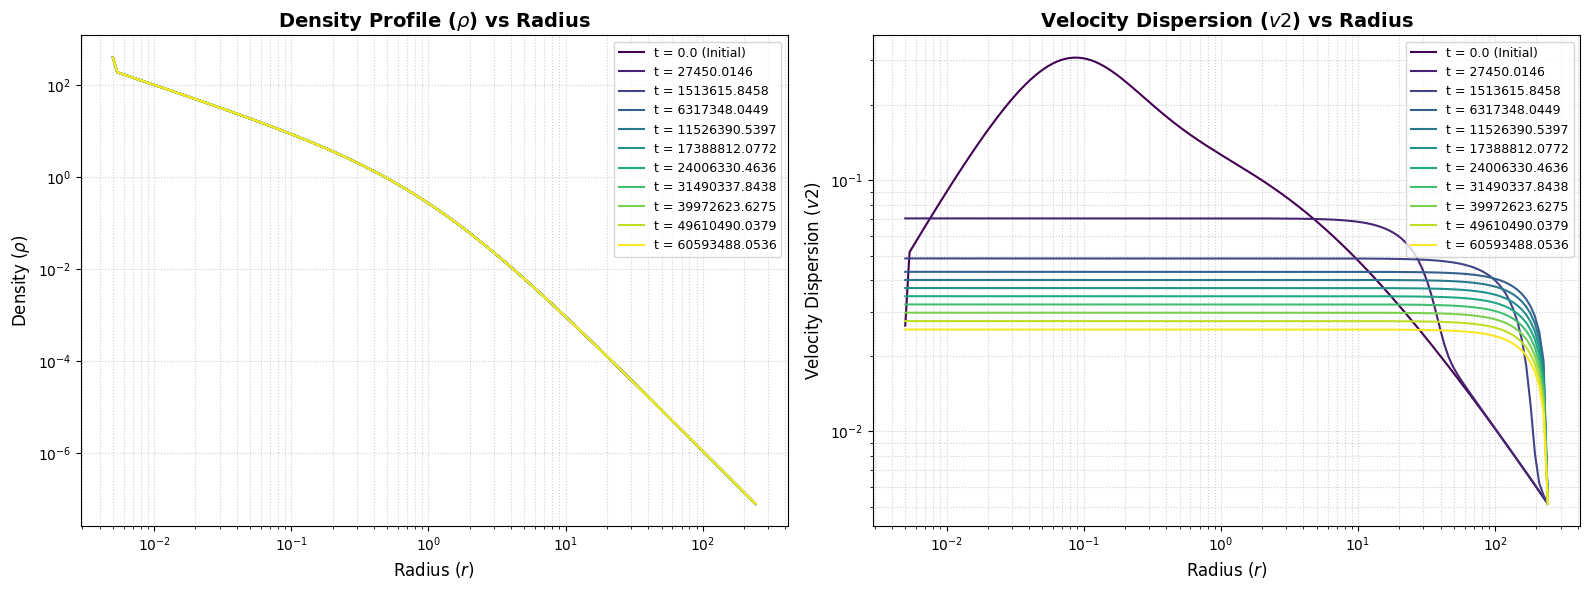

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import re

# 1. Read the Output File
def read_gravothermal_output(filename):
    with open(filename, 'r') as f:
        lines = f.readlines()

    # Skip the 14 header lines
    raw_data = "".join(lines[14:])

    # Extract all arrays enclosed in brackets [ ... ]
    array_strings = re.findall(r'\[(.*?)\]', raw_data, re.DOTALL)

    # Remove all the arrays from the text to leave behind only the time/step lines
    time_step_text = re.sub(r'\[.*?\]', '', raw_data, flags=re.DOTALL)
    time_lines = [line.strip() for line in time_step_text.split('\n') if line.strip()]

    snapshots = []

    # Each time snapshot consists of 1 time line and 5 arrays (R, Rho, M, u, L)
    for i, t_line in enumerate(time_lines):
        t_val, step_val = map(float, t_line.split())

        idx = i * 5
        r_arr   = np.fromstring(array_strings[idx], sep=' ')
        rho_arr = np.fromstring(array_strings[idx+1], sep=' ')
        m_arr   = np.fromstring(array_strings[idx+2], sep=' ')
        u_arr   = np.fromstring(array_strings[idx+3], sep=' ')
        l_arr   = np.fromstring(array_strings[idx+4], sep=' ')

        snapshots.append({
            'time': t_val,
            'step': int(step_val),
            'r': r_arr,
            'rho': rho_arr,
            'M': m_arr,
            'u': u_arr,
            'L': l_arr
        })

    return snapshots

# 2. Extract Data
snapshots = read_gravothermal_output(output_file)
print(f"Successfully loaded {len(snapshots)} time snapshots.")

# 3. Create Plots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Generate a color map so early times are one color and late times are another
colors = plt.cm.viridis(np.linspace(0, 1, len(snapshots)))

for i, snap in enumerate(snapshots):
    t_label = f"t = {snap['time']:.4f}" if snap['time'] > 0 else "t = 0.0 (Initial)"

    # Calculate Velocity Dispersion from Internal Energy: v = sqrt((2/3) * u)
    v_dispersion = 2.0 / 3.0 * snap['u']

    # Panel 1: Density (rho) vs Radius (r)
    axes[0].plot(snap['r'], snap['rho'], label=t_label, color=colors[i], lw=1.5)

    # Panel 2: Velocity Dispersion (v) vs Radius (r)
    axes[1].plot(snap['r'], v_dispersion, label=t_label, color=colors[i], lw=1.5)

# 4. Format Panel 1 (Density)
axes[0].set_title('Density Profile ($\\rho$) vs Radius', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Radius ($r$)', fontsize=12)
axes[0].set_ylabel('Density ($\\rho$)', fontsize=12)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].grid(True, which="both", ls=":", alpha=0.6)
axes[0].legend(loc='best', fontsize=9)

# 5. Format Panel 2 (Velocity Dispersion)
axes[1].set_title('Velocity Dispersion ($v2$) vs Radius', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Radius ($r$)', fontsize=12)
axes[1].set_ylabel('Velocity Dispersion ($v2$)', fontsize=12)
axes[1].set_xscale('log')
axes[1].set_yscale('log') # Can be changed to 'linear' if v doesn't span multiple magnitudes
axes[1].grid(True, which="both", ls=":", alpha=0.6)
axes[1].legend(loc='best', fontsize=9)

plt.tight_layout()
plt.show()